<a href="https://colab.research.google.com/github/zogydinesh/ITA-0616/blob/main/program7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Rows: 768  Features: 8
Class counts: {0: 500, 1: 268} 

Train size: 614  Test size: 154 

Epoch    1  Loss = 0.6931
Epoch  200  Loss = 0.4696
Epoch  400  Loss = 0.4674
Epoch  600  Loss = 0.4673
Epoch  800  Loss = 0.4673
Epoch 1000  Loss = 0.4673

Confusion Matrix (rows = actual, columns = predicted):
                 No diabetes (0)  Diabetes (1)
No diabetes (0)               85            11
Diabetes (1)                  27            31

Train accuracy: 78.99%
Test accuracy:  75.32%
Precision: 0.74   Recall: 0.53

Feature weights (bigger = more influence on diabetes):
  Pregnancies       +0.412
  Glucose           +1.178
  BloodPressure     -0.228
  SkinThickness     +0.055
  Insulin           -0.197
  BMI               +0.638
  DiabetesPedigree  +0.327
  Age               +0.154

New patient: [2.0, 130.0, 70.0, 25.0, 100.0, 32.0, 0.5, 35.0]
Probability of diabetes: 0.32  ->  Predicted class: 0


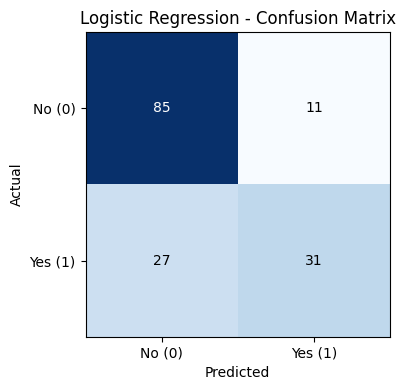

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Dataset: Pima Indians Diabetes - UCI / NIDDK
# Automatically downloading from a reliable public mirror of the dataset
url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv"

# ---- 1. Load CSV ----
cols = ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness',
        'Insulin', 'BMI', 'DiabetesPedigree', 'Age', 'Outcome']
df = pd.read_csv(url, header=None, names=cols)
X = df.drop(columns='Outcome').values.astype(float)
y = df['Outcome'].values
print("Rows:", len(df), " Features:", X.shape[1])
print("Class counts:", {0: int((y == 0).sum()), 1: int((y == 1).sum())}, "\n")

# ---- 2. Train / test split (80% / 20%) ----
np.random.seed(42)
idx = np.random.permutation(len(X))
split = int(0.8 * len(X))
Xtr, Xte = X[idx[:split]], X[idx[split:]]
ytr, yte = y[idx[:split]], y[idx[split:]]

# ---- 3. Standardize inputs (using training mean and std) ----
mu, sd = Xtr.mean(axis=0), Xtr.std(axis=0)
Xtr = (Xtr - mu) / sd
Xte = (Xte - mu) / sd
print("Train size:", len(Xtr), " Test size:", len(Xte), "\n")

# ---- 4. Logistic Regression with Gradient Descent ----
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

w = np.zeros(Xtr.shape[1])
b = 0.0
lr, epochs = 0.1, 1000

for epoch in range(1, epochs + 1):
    p = sigmoid(Xtr @ w + b)                       # predicted probability
    loss = -np.mean(ytr * np.log(p + 1e-12) + (1 - ytr) * np.log(1 - p + 1e-12))
    grad_w = Xtr.T @ (p - ytr) / len(ytr)          # gradient of loss
    grad_b = np.mean(p - ytr)
    w -= lr * grad_w                               # update weights
    b -= lr * grad_b
    if epoch == 1 or epoch % 200 == 0:
        print(f"Epoch {epoch:4d}  Loss = {loss:.4f}")

# ---- 5. Prediction (probability >= 0.5 means class 1) ----
def predict(Xin):
    return (sigmoid(Xin @ w + b) >= 0.5).astype(int)

pred = predict(Xte)

# ---- 6. Confusion matrix ----
cm = np.zeros((2, 2), dtype=int)
for a, p in zip(yte, pred):
    cm[a, p] += 1

print("\nConfusion Matrix (rows = actual, columns = predicted):")
print(pd.DataFrame(cm, index=['No diabetes (0)', 'Diabetes (1)'],
                   columns=['No diabetes (0)', 'Diabetes (1)']))

# ---- 7. Accuracy, precision, recall ----
accuracy = np.trace(cm) / cm.sum() * 100
precision = cm[1, 1] / (cm[1, 1] + cm[0, 1]) if (cm[1, 1] + cm[0, 1]) > 0 else 0.0
recall = cm[1, 1] / (cm[1, 1] + cm[1, 0]) if (cm[1, 1] + cm[1, 0]) > 0 else 0.0
print(f"\nTrain accuracy: {np.mean(predict(Xtr) == ytr) * 100:.2f}%")
print(f"Test accuracy:  {accuracy:.2f}%")
print(f"Precision: {precision:.2f}   Recall: {recall:.2f}")

# ---- 8. Learned weights ----
print("\nFeature weights (bigger = more influence on diabetes):")
for name, wt in zip(cols[:-1], w):
    print(f"  {name:<17} {wt:+.3f}")

# ---- 9. Classify a new patient ----
new = np.array([[2, 130, 70, 25, 100, 32.0, 0.5, 35]])
prob = sigmoid(((new - mu) / sd) @ w + b)[0]
print("\nNew patient:", new[0].tolist())
print(f"Probability of diabetes: {prob:.2f}  ->  Predicted class: {int(prob >= 0.5)}")

# ---- 10. Plot the confusion matrix ----
fig, ax = plt.subplots(figsize=(5, 4))
ax.imshow(cm, cmap='Blues')
ax.set_xticks([0, 1])
ax.set_xticklabels(['No (0)', 'Yes (1)'])
ax.set_yticks([0, 1])
ax.set_yticklabels(['No (0)', 'Yes (1)'])
ax.set_xlabel('Predicted')
ax.set_ylabel('Actual')
ax.set_title('Logistic Regression - Confusion Matrix')
for i in range(2):
    for j in range(2):
        ax.text(j, i, cm[i, j], ha='center', va='center',
                color='white' if cm[i, j] > cm.max() / 2 else 'black')
plt.tight_layout()
plt.show()